In [48]:
#Importing the required libraries
from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pyplot as plt

In [49]:
#Generate a synthetic dataset
X, y = make_classification(n_samples=100, n_features=2, n_informative=1,n_redundant=0,
                           n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=10)

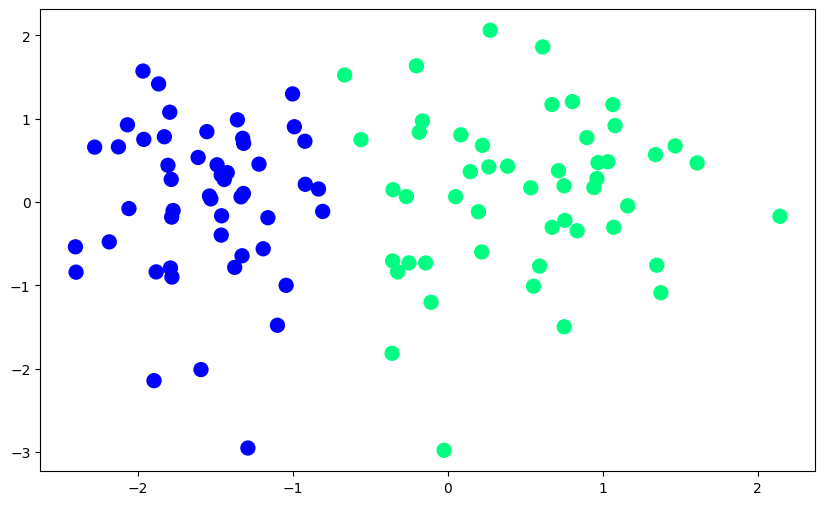

In [50]:
#Plotting the dataset
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.show()

As evident, the data is linearly seperable having two classes (1-Green, 0-Blue)

We've defined a function "perceptron", which returns the weights upon training it with the dataset

In [51]:
def perceptron(X,y):

    X = np.insert(X,0,1,axis=1) # We've insterted another column of 1s in our input dataset
    weights = np.ones(X.shape[1]) # Initializing the weights with 1s
    lr = 0.1 # Initializing the Learning Rate

    for i in range(1000): # Epoch=1000
        j = np.random.randint(0,100) # Selecting a random number between 0 and 100. 100 being the number of points in our dataset
        y_hat = step(np.dot(X[j],weights)) # Predicting the model's prediction for the jth data point (0 or 1)
        weights = weights + lr*(y[j]-y_hat)*X[j] # This is our formula for updating the weights

    return weights[0],weights[1:]


In [52]:
#We define a function that returns 1 if the input is >0, and returns 0 if the input is <0
def step(z):
    return 1 if z>0 else 0

In [53]:
#Invoking the perceptron function
intercept_,coef_ = perceptron(X,y)

In [54]:
#Printing the Intercept and Coefficient values
print(coef_)
print(intercept_)

[1.31531081 0.11744913]
1.0


In [55]:
#Finding the Slope and y-Intercept
m = -(coef_[0]/coef_[1]) #Slope value
b = -(intercept_/coef_[1]) #y-Intercept value

In [56]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + b

(-3.0, 2.0)

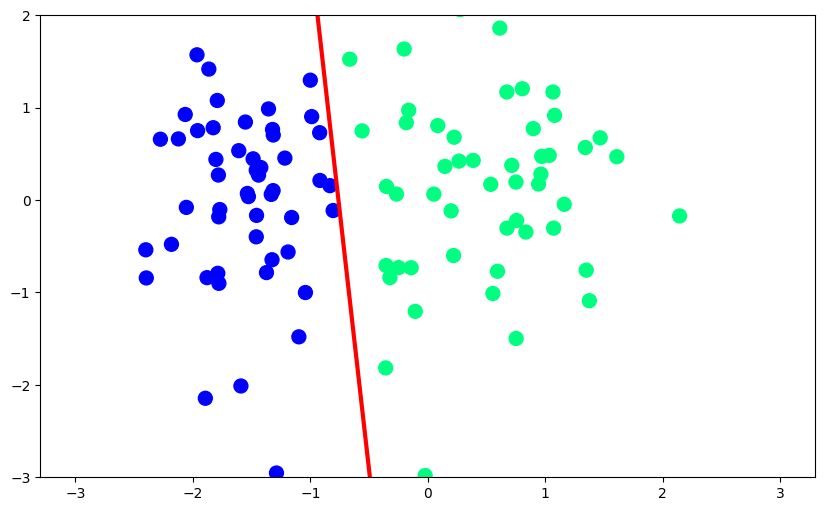

In [57]:
#Plottig the Classification Line
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

**Animation:**

---

In [67]:
import matplotlib.animation as animation
from IPython.display import HTML, display
import ipywidgets as widgets

# We will reuse the 'step' function and track the changes in weights
def train_perceptron_history(X, y, epochs=100, lr=0.1):
    X_bias = np.insert(X, 0, 1, axis=1)
    weights = np.ones(X_bias.shape[1])
    history = [weights.copy()]

    for i in range(epochs):
        j = np.random.randint(0, len(X))
        y_hat = step(np.dot(X_bias[j], weights))
        weights = weights + lr * (y[j] - y_hat) * X_bias[j]
        history.append(weights.copy())
    return history

# Create a function that builds and displays the animation
def animate_perceptron(epochs, lr):
    weights_history = train_perceptron_history(X, y, epochs=epochs, lr=lr)

    # Create the animation plot
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='winter', s=100)
    ax.set_ylim(-3, 2)
    ax.set_xlim(-3, 3)

    x_vals = np.linspace(-3, 3, 100)
    line, = ax.plot([], [], color='red', linewidth=3)
    title_text = ax.set_title("")

    def init():
        line.set_data([], [])
        title_text.set_text("Step: 0")
        return line, title_text

    def animate(frame):
        weights = weights_history[frame]
        intercept = weights[0]
        coef = weights[1:]

        if coef[1] != 0:
            m_curr = -(coef[0] / coef[1])
            b_curr = -(intercept / coef[1])
            y_vals = m_curr * x_vals + b_curr
        else:
            y_vals = np.zeros_like(x_vals)

        line.set_data(x_vals, y_vals)
        title_text.set_text(f"Step: {frame} (LR: {lr})")
        return line, title_text

    ani = animation.FuncAnimation(fig, animate, init_func=init, frames=len(weights_history), interval=50, blit=True)
    plt.close(fig)
    display(HTML(ani.to_jshtml()))

# Create the interactive controls
widgets.interact_manual(
    animate_perceptron,
    epochs=widgets.IntSlider(min=10, max=500, step=10, value=150, description='Epochs:'),
    lr=widgets.FloatSlider(min=0.01, max=1.0, step=0.05, value=0.1, description='LR:')
);

interactive(children=(IntSlider(value=150, description='Epochs:', max=500, min=10, step=10), FloatSlider(value…